In [ ]:
# Purpose:
#   Quantify patient-level PBMC cell-type composition and test for compositional differences
#   across disease stages (within race) and across races (within stage), using ScanPro-derived
#   p-values, then visualize distributions as faceted boxplots with significance annotations.
#
# Summary:
#   - Load patient metadata (meta_pt.csv) and define ordered race-stage groups
#   - Load integrated single-cell AnnData (ft_all.h5ad) with final level-3 celltype labels
#   - Build a celltype × patient count matrix and convert to per-patient proportions
#   - Convert proportions to *within–major-lineage* ratios (B/T/DC/Mono/NK), then scale to %
#   - Merge ratios with patient metadata and save an analysis-ready CSV
#   - Create a multi-panel boxplot grid (one panel per level-3 cell type):
#       (1) disease state comparisons within each race (NHW: HRL/DCIS/BC; NHB: HRL/DCIS/BC)
#       (2) race comparisons within each stage (HRL/DCIS/BC: NHW vs NHB)
#   - Export publication-ready SVG figures and separate color legend SVGs

# Header

In [1]:
from utils import *
import math
from scanpro import scanpro

In [2]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [3]:
os.chdir('../')

# Load data

In [5]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', index_col=0)

print(len(meta['dataset_name'].unique()))

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL', 'NHW-DCIS', 'NHW-BC','NHB-HRL', 'NHB-DCIS', 'NHB-BC'],
    ordered=True
    )

meta

55


,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,N,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,N,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [41]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)

dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3', 'sampleid', 'batch',
       'viability_pct', 'group', 'race', 'age', 'diabetes', 'obesity',
       'race_stage'],
      dtype='object')

In [8]:
Counter(dat.obs['race_stage'])

Counter({'NHB-HRL': 96083,
         'NHW-BC': 96038,
         'NHW-HRL': 88512,
         'NHB-BC': 85505,
         'NHW-DCIS': 45203,
         'NHB-DCIS': 23224})

In [9]:
with open('data/Legends/celltypelevel3_palette.pkl', 'rb') as f:
    
    celltype_palette = pkl.load(f)

    
celltype_palette

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

In [11]:
meta_ordered = meta.sort_values([
    'race-stage','age'
]).set_index('dataset_name',drop=True)
    
pt_ordered = meta_ordered.index.tolist()


meta_ordered

,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
dataset_name,,,,,,,,
Pool137_14,1,91,HRL,NHW,42.5,N,Y,NHW-HRL
Pool138_15,2,89,HRL,NHW,42.8,N,N,NHW-HRL
Pool138_14,2,93,HRL,NHW,43.7,N,N,NHW-HRL
Pool137_26,1,91,HRL,NHW,53.1,N,N,NHW-HRL
Pool138_9,2,98,HRL,NHW,57.7,N,Y,NHW-HRL
Pool137_25,1,90,HRL,NHW,59.6,N,N,NHW-HRL
Pool137_29,1,90,HRL,NHW,59.6,N,N,NHW-HRL
Pool138_4,2,94,HRL,NHW,60.5,N,Y,NHW-HRL
Pool137_10,1,88,HRL,NHW,62.3,N,N,NHW-HRL


In [13]:
ct = pd.crosstab(dat.obs['celltype_level3'], 
                   dat.obs['dataset_name'])
ct = ct.loc[:, pt_ordered]

pct = ct.div(ct.sum(axis=0))  #.sum(axis=0)

pct.index.name = None              # Remove the outer index name
pct.columns.name = None    

pct

,Pool137_14,Pool138_15,Pool138_14,Pool137_26,Pool138_9,Pool137_25,Pool137_29,Pool138_4,Pool137_10,Pool137_6,...,Pool138_19,Pool138_27,Pool137_31,Pool137_17,Pool137_16,Pool138_18,Pool138_29,Pool138_17,Pool138_20,Pool138_26
Naive B,0.070151,0.014172,0.078019,0.032960,0.053535,0.027157,0.063164,0.092120,0.018101,0.035602,...,0.037791,0.076304,0.141325,0.092935,0.058410,0.038982,0.167568,0.036818,0.020859,0.031377
Mature B,0.037312,0.043600,0.029102,0.047433,0.034138,0.101278,0.029163,0.013315,0.007835,0.035301,...,0.041969,0.024830,0.025737,0.071944,0.049793,0.059666,0.046708,0.018197,0.015644,0.023533
Memory B,0.011674,0.016339,0.016409,0.011409,0.017457,0.023802,0.014783,0.012681,0.003647,0.025988,...,0.054869,0.021769,0.012417,0.023303,0.030482,0.030231,0.009632,0.014177,0.005061,0.009413
Plasmablast,0.001418,0.000903,0.004747,0.000845,0.000485,0.001278,0.002553,0.001359,0.000810,0.001052,...,0.018714,0.004082,0.001129,0.003329,0.004309,0.001591,0.000000,0.001693,0.001687,0.001569
Naive CD4T,0.179577,0.161943,0.183695,0.145362,0.133450,0.111342,0.113291,0.197917,0.170066,0.103650,...,0.103743,0.065420,0.112428,0.069262,0.129907,0.180854,0.209658,0.139018,0.176687,0.066677
Central Memory CD4T,0.206306,0.159054,0.157688,0.165434,0.266996,0.175240,0.125521,0.238043,0.213292,0.167793,...,0.170967,0.252041,0.182978,0.204365,0.238270,0.194113,0.217971,0.378756,0.149693,0.161751
Effector Memory CD4T,0.028148,0.025636,0.025284,0.028417,0.051886,0.043131,0.013036,0.035417,0.021883,0.025387,...,0.031613,0.034467,0.022463,0.031441,0.020109,0.013789,0.021903,0.067076,0.015031,0.023376
Cytotoxic CD4T,0.002182,0.002166,0.000929,0.001796,0.001455,0.003355,0.005913,0.001993,0.001621,0.001652,...,0.002544,0.000680,0.001129,0.001295,0.001915,0.004243,0.001451,0.005290,0.006442,0.000784
Treg,0.024220,0.015075,0.014138,0.011832,0.018718,0.011342,0.006585,0.023732,0.011617,0.014271,...,0.014172,0.018707,0.012643,0.017662,0.023779,0.009281,0.026125,0.030047,0.026227,0.019925
Naive CD8T,0.072660,0.071222,0.071723,0.026410,0.016099,0.028115,0.058729,0.031069,0.034986,0.013820,...,0.096839,0.071882,0.095270,0.043277,0.040696,0.037125,0.017944,0.041684,0.008129,0.006903


# By disease states
Pct of the main cell lineage

## Calc %

In [55]:
cells_ordered = [
    'Naive B','Mature B','Memory B','Plasmablast',
    'Naive CD4T','Central Memory CD4T','Effector Memory CD4T','Cytotoxic CD4T','Treg',
    'Naive CD8T','Central Memory CD8T','Effector Memory CD8T',
    'Double Negative T','γδ T','MAIT',
    'cDC1','cDC2','pDC',
    'Classical Monocyte','Intermediate Monocyte','Nonclassical Monocyte','Cytotoxic Monocyte',
    'CD56-dim NK','CD56-bright NK','Proliferating NK'
]


In [56]:
cells_group = {
    'B':[
 'Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    
    'T':[
 'Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    
    'DC':[
 'cDC1',
 'cDC2',
 'pDC'     
    ],
    
    'Mono':[
 'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    
    'NK':[
 'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}


In [57]:
new_pct = pd.DataFrame(index=pct.index, columns=pct.columns)

for group, cell_list in cells_group.items():
    # For each group, get the total per sample (across all group members)
    group_sum = pct.loc[cell_list].sum(axis=0)
    # Recalculate each member as a fraction of its group
    for cell in cell_list:
        new_pct.loc[cell] = pct.loc[cell] / group_sum

new_pct = new_pct.fillna(0) * 100
new_pct

dataset_name,Pool137_14,Pool138_15,Pool138_14,Pool137_26,Pool138_9,Pool137_25,Pool137_29,Pool138_4,Pool137_10,Pool137_6,...,Pool138_19,Pool138_27,Pool137_31,Pool137_17,Pool137_16,Pool138_18,Pool138_29,Pool138_17,Pool138_20,Pool138_26
Naive B,58.190045,18.892900,60.820595,35.575827,50.688705,17.689906,57.598039,77.103867,59.555556,36.349693,...,24.644550,60.089286,78.250000,48.527282,40.848214,29.878049,74.837949,51.940299,48.226950,47.619048
Mature B,30.950226,58.122744,22.687047,51.197263,32.323232,65.972945,26.593137,11.144807,25.777778,36.042945,...,27.369668,19.553571,14.250000,37.566393,34.821429,45.731707,20.860342,25.671642,36.170213,35.714286
Memory B,9.683258,21.780987,12.791633,12.314709,16.528926,15.504683,13.480392,10.614102,12.000000,26.533742,...,35.781991,17.142857,6.875000,12.168035,21.316964,23.170732,4.301709,20.000000,11.702128,14.285714
Plasmablast,1.176471,1.203369,3.700724,0.912201,0.459137,0.832466,2.328431,1.137225,2.666667,1.073620,...,12.203791,3.214286,0.625000,1.738291,3.013393,1.219512,0.000000,2.388060,3.900709,2.380952
Naive CD4T,31.478294,31.011236,35.240546,31.237230,19.293326,27.913496,30.958502,33.834004,33.627137,19.508058,...,21.563444,14.222332,24.782284,16.353712,25.629723,34.707379,34.062165,17.335092,36.583042,19.495413
Central Memory CD4T,36.163702,30.458081,30.251435,35.550511,38.600673,43.932719,34.300404,40.693713,42.174145,31.580435,...,35.536254,54.794183,40.333416,48.253275,47.008816,37.251908,35.412647,47.229551,30.993966,47.293578
Effector Memory CD4T,4.934022,4.909248,4.850525,6.106697,7.501402,10.812976,3.562248,6.054506,4.326923,4.778061,...,6.570997,7.493222,4.951480,7.423581,3.967254,2.646310,3.558414,8.364116,3.112099,6.834862
Cytotoxic CD4T,0.382482,0.414866,0.178183,0.385925,0.210320,0.841009,1.615865,0.340663,0.320513,0.310998,...,0.528701,0.147893,0.248818,0.305677,0.377834,0.814249,0.235798,0.659631,1.333757,0.229358
Treg,4.245554,2.886776,2.712334,2.542565,2.706113,2.843412,1.799486,4.056984,2.297009,2.685892,...,2.945619,4.067045,2.786763,4.170306,4.691436,1.781170,4.244373,3.746702,5.430295,5.825688
Naive CD8T,12.736661,13.638721,13.759652,5.675369,2.327538,7.048458,16.048476,5.311242,6.917735,2.601074,...,20.128399,15.627311,21.000249,10.218341,8.028967,7.124682,2.915327,5.197889,1.683074,2.018349


In [58]:
pct_T = new_pct.T
pct_T.index.name = 'dataset_name'

pct_T_reset = pct_T.reset_index()
meta_reset = meta_ordered.reset_index()

dfp = pd.merge(pct_T_reset, meta_reset, on='dataset_name', how='inner')
dfp

,dataset_name,Naive B,Mature B,Memory B,Plasmablast,Naive CD4T,Central Memory CD4T,Effector Memory CD4T,Cytotoxic CD4T,Treg,...,CD56-bright NK,Proliferating NK,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
0,Pool137_14,58.190045,30.950226,9.683258,1.176471,31.478294,36.163702,4.934022,0.382482,4.245554,...,7.512953,1.208981,1,91,HRL,NHW,42.5,N,Y,NHW-HRL
1,Pool138_15,18.892900,58.122744,21.780987,1.203369,31.011236,30.458081,4.909248,0.414866,2.886776,...,15.130435,1.391304,2,89,HRL,NHW,42.8,N,N,NHW-HRL
2,Pool138_14,60.820595,22.687047,12.791633,3.700724,35.240546,30.251435,4.850525,0.178183,2.712334,...,9.687034,2.384501,2,93,HRL,NHW,43.7,N,N,NHW-HRL
3,Pool137_26,35.575827,51.197263,12.314709,0.912201,31.237230,35.550511,6.106697,0.385925,2.542565,...,11.111111,0.750751,1,91,HRL,NHW,53.1,N,N,NHW-HRL
4,Pool138_9,50.688705,32.323232,16.528926,0.459137,19.293326,38.600673,7.501402,0.210320,2.706113,...,4.545455,1.704545,2,98,HRL,NHW,57.7,N,Y,NHW-HRL
5,Pool137_25,17.689906,65.972945,15.504683,0.832466,27.913496,43.932719,10.812976,0.841009,2.843412,...,14.356436,4.455446,1,90,HRL,NHW,59.6,N,N,NHW-HRL
6,Pool137_29,57.598039,26.593137,13.480392,2.328431,30.958502,34.300404,3.562248,1.615865,1.799486,...,7.022472,1.966292,1,90,HRL,NHW,59.6,N,N,NHW-HRL
7,Pool138_4,77.103867,11.144807,10.614102,1.137225,33.834004,40.693713,6.054506,0.340663,4.056984,...,10.821382,1.173403,2,94,HRL,NHW,60.5,N,Y,NHW-HRL
8,Pool137_10,59.555556,25.777778,12.000000,2.666667,33.627137,42.174145,4.326923,0.320513,2.297009,...,4.077670,2.135922,1,88,HRL,NHW,62.3,N,N,NHW-HRL
9,Pool137_6,36.349693,36.042945,26.533742,1.073620,19.508058,31.580435,4.778061,0.310998,2.685892,...,6.934307,2.189781,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [59]:
dfp.to_csv('data/Figure2/ratio_majorCellTypes.csv')

## Plot

In [78]:
# p values and FDRs
res = pd.read_csv('data/Figure2/scanpro_withineachrace_compareStages_withinMajorCelltype.csv', 
                  index_col=0)

In [79]:
res[res['p_values']<0.05].sort_values(['celltype'])

,mean_props_HRL,mean_props_DCIS,prop_ratio,t_statistics,p_values,adjusted_p_values,comparison,celltype,mean_props_BC,subgroup
32,0.000000,0.003070,0.508582,-2.304350,0.029330,0.715913,BC vs DCIS,Cytotoxic CD4T,0.001561,NHW
31,0.000000,0.041393,0.613420,-2.114032,0.044448,0.296383,BC vs DCIS,Effector Memory CD4T,0.025392,NHB
64,0.018078,0.000000,0.544632,-2.122687,0.043649,0.419656,BC vs HRL,MAIT,0.009846,NHB
24,0.001319,0.000866,0.656209,-2.146012,0.041562,0.346347,DCIS vs HRL,Proliferating NK,0.000000,NHB
8,0.016395,0.031609,1.928006,3.054125,0.005224,0.130611,DCIS vs HRL,Treg,0.000000,NHB
33,0.000000,0.031609,0.549492,-3.154888,0.004085,0.102113,BC vs DCIS,Treg,0.017369,NHB
16,0.009906,0.005780,0.583460,-2.645991,0.013754,0.171931,DCIS vs HRL,cDC2,0.000000,NHB
41,0.000000,0.005780,2.046491,2.845109,0.008631,0.107887,BC vs DCIS,cDC2,0.011828,NHB
38,0.000000,0.000480,0.462681,-2.082967,0.047421,0.296383,BC vs DCIS,γδ T,0.000222,NHB
63,0.000746,0.000000,0.297928,-4.549368,0.000115,0.002869,BC vs HRL,γδ T,0.000222,NHB


In [82]:
celltypes_sel = res[res['p_values']<0.05]['celltype'].unique()
celltypes_sel

array(['Cytotoxic CD4T', 'Treg', 'cDC2', 'Proliferating NK',
       'Effector Memory CD4T', 'γδ T', 'MAIT'], dtype=object)

In [99]:
ratio = pd.read_csv('data/Figure2/ratio_majorCellTypes.csv', index_col=0)
ratio

,dataset_name,Naive B,Mature B,Memory B,Plasmablast,Naive CD4T,Central Memory CD4T,Effector Memory CD4T,Cytotoxic CD4T,Treg,...,CD56-bright NK,Proliferating NK,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
0,Pool137_14,58.190045,30.950226,9.683258,1.176471,31.478294,36.163702,4.934022,0.382482,4.245554,...,7.512953,1.208981,1,91,HRL,NHW,42.5,N,Y,NHW-HRL
1,Pool138_15,18.892900,58.122744,21.780987,1.203369,31.011236,30.458081,4.909248,0.414866,2.886776,...,15.130435,1.391304,2,89,HRL,NHW,42.8,N,N,NHW-HRL
2,Pool138_14,60.820595,22.687047,12.791633,3.700724,35.240546,30.251435,4.850525,0.178183,2.712334,...,9.687034,2.384501,2,93,HRL,NHW,43.7,N,N,NHW-HRL
3,Pool137_26,35.575827,51.197263,12.314709,0.912201,31.237230,35.550511,6.106697,0.385925,2.542565,...,11.111111,0.750751,1,91,HRL,NHW,53.1,N,N,NHW-HRL
4,Pool138_9,50.688705,32.323232,16.528926,0.459137,19.293326,38.600673,7.501402,0.210320,2.706113,...,4.545455,1.704545,2,98,HRL,NHW,57.7,N,Y,NHW-HRL
5,Pool137_25,17.689906,65.972945,15.504683,0.832466,27.913496,43.932719,10.812976,0.841009,2.843412,...,14.356436,4.455446,1,90,HRL,NHW,59.6,N,N,NHW-HRL
6,Pool137_29,57.598039,26.593137,13.480392,2.328431,30.958502,34.300404,3.562248,1.615865,1.799486,...,7.022472,1.966292,1,90,HRL,NHW,59.6,N,N,NHW-HRL
7,Pool138_4,77.103867,11.144807,10.614102,1.137225,33.834004,40.693713,6.054506,0.340663,4.056984,...,10.821382,1.173403,2,94,HRL,NHW,60.5,N,Y,NHW-HRL
8,Pool137_10,59.555556,25.777778,12.000000,2.666667,33.627137,42.174145,4.326923,0.320513,2.297009,...,4.077670,2.135922,1,88,HRL,NHW,62.3,N,N,NHW-HRL
9,Pool137_6,36.349693,36.042945,26.533742,1.073620,19.508058,31.580435,4.778061,0.310998,2.685892,...,6.934307,2.189781,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [100]:
#test
from statannotations.Annotator import Annotator
from scipy.stats import f_oneway

dfp = ratio.copy()

dfp['race-stage'] = pd.Categorical(
    dfp['race-stage'],
    categories=['NHW-HRL','NHW-DCIS','NHW-BC', 
                'NHB-HRL','NHB-DCIS','NHB-BC'],
    ordered=True
    )

color_set = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830',

    'Diabetes':'navy',
    'Obesity':'salmon'

}


cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}



# Define the group for each pair (extract the trailing substring after '-' from NHW-HRL, etc.)
def get_race(pair):
    # E.g., ('NHB-HRL', 'NHB-DCIS') -> 'NHB'
    return pair[0].split('-')[0]

def get_comparison(pair):
    # E.g., ('NHB-DCIS', 'NHB-HRL') -> 'DCIS vs HRL'
    a = pair[0].split('-')[1]
    b = pair[1].split('-')[1]
    return f'{a} vs {b}'


def pval_to_star(p):
    # Customize as you wish (this is standard)
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

def get_group_from_celltype(celltype, cells_group):
    for group, members in cells_group.items():
        if celltype == members or celltype in members:
            return group
    return None



# --------- Settings ---------
ncol = 5
features = [x for x in cells_ordered if x in dfp.columns]#[x for x in cells_ordered if x in celltypes_sel]   # the cell type names
nrow = int(np.ceil(len(features)/ncol))
figwidth = 7
figheight = nrow * 1.3    # or adjust as needed

fig, axs = plt.subplots(nrow, ncol, figsize=(figwidth, figheight), sharex=True)
# fig.subplots_adjust(wspace=0.4)

axs = axs.flatten()

for i, yname in enumerate(features):
    ax = axs[i]
    sns.boxplot(
        data=dfp,
        x='race-stage',
        y=yname,
        hue='race-stage',
        palette=color_set,
        flierprops=dict(marker='o', markersize=2, alpha=0.7),
        ax=ax,
        showfliers=True
    )
    sns.stripplot(
        data=dfp, x='race-stage', y=yname, size=2, color='black', alpha=.3, ax=ax
    )
    
    n_cat = dfp['race-stage'].nunique()
    split_x = n_cat / 2 - 0.5   # 6 → 2.5
    
    ax.axvline(
        x=split_x,
        linestyle=':',
        color='gray',
        alpha=0.5,
        linewidth=1
    )

    
    pairs = [
        ('NHW-DCIS', 'NHW-HRL'),('NHW-BC', 'NHW-DCIS'),('NHW-BC', 'NHW-HRL'),
        ('NHB-DCIS', 'NHB-HRL'),('NHB-BC', 'NHB-DCIS'),('NHB-BC', 'NHB-HRL')
    ]
    
    # --- Prepare custom pvalues (and stars) ---
    custom_annotations = []
    for pair in pairs:
        race = get_race(pair)
        comparison = get_comparison(pair)
        # Get p-value from res for this celltype and group
        try:
            p = res[(res['celltype']==yname) &
                (res['subgroup']==race) &
                (res['comparison']==comparison)
                ]['p_values'].iloc[0]
        except Exception:
            p = 1.0  # fallback if not found
        # Convert to star (or keep as e.g. f"p={p:.2g}")
        custom_annotations.append(p)

    annotator = Annotator(
        ax, pairs, data=dfp, x='race-stage', y=yname
    )
    
    annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', comparisons_correction=None, hide_non_significant=True)
    annotator.apply_and_annotate()


    groupname = get_group_from_celltype(yname, cells_group)


    ax.set_title(yname, fontsize=7, color='k', fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(f'Percentage of {groupname} cells')  # Hide to save space
    ax.tick_params(axis='x', labelsize=6, rotation=90)
    ax.tick_params(axis='y', labelsize=6)
    ax.legend([],[], frameon=False)  # Remove legend

    # for tick_label in ax.get_xticklabels():
    #     group = tick_label.get_text()
    #     if group in color_set:
    #         tick_label.set_color(color_set[group])

# Hide any unused subplots
for j in range(i+1, len(axs)):
    axs[j].set_visible(False)


group_palette = {
    'NHW': '#95AAD3',   # blue
    'NHB': '#E07F80'  # pink
}

# Mapping from tick positions (0-based index) to group labels
tick_groups = {
    (0, 2): 'NHW',
    (3, 5): 'NHB'
}

#Add colored bars under x-axis ticks
# for ax in axs:
#     if not ax.get_visible():
#         continue  # skip hidden axes
    
#     # Find y_min so the colored bar is just below the plot
#     y_min = ax.get_ylim()[0]
#     y_offset = (ax.get_ylim()[1] - y_min) * 0.02  # a tiny offset
    
#     for (start_idx, end_idx), group in tick_groups.items():
#         ax.axvspan(
#             start_idx - 0.4,  # left edge
#             end_idx + 0.4,    # right edge
#             ymin=-0.02, ymax=0.0,  # relative to y-axis in axis coords
#             color=group_palette[group],
#             transform=ax.get_xaxis_transform(),  # align with x-axis
#             clip_on=False,
#             zorder=-1
#         )

        

# Shared axis label
fig.text(0.5, 0.04, '', ha='center', fontsize=7)
# fig.text(0.03, 0.5, 'Percentage of', va='center', rotation='vertical', fontsize=7)


plt.tight_layout(rect=[0.04, 0.04, 1, 1])  # leave space for axis labels
plt.savefig('plots/F2/cellpctbox_byStage_withinMajorCelltype.svg', bbox_inches='tight', dpi=600)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHB-HRL vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided, P_val:2.769e-02 U_stat=2.900e+01
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***:

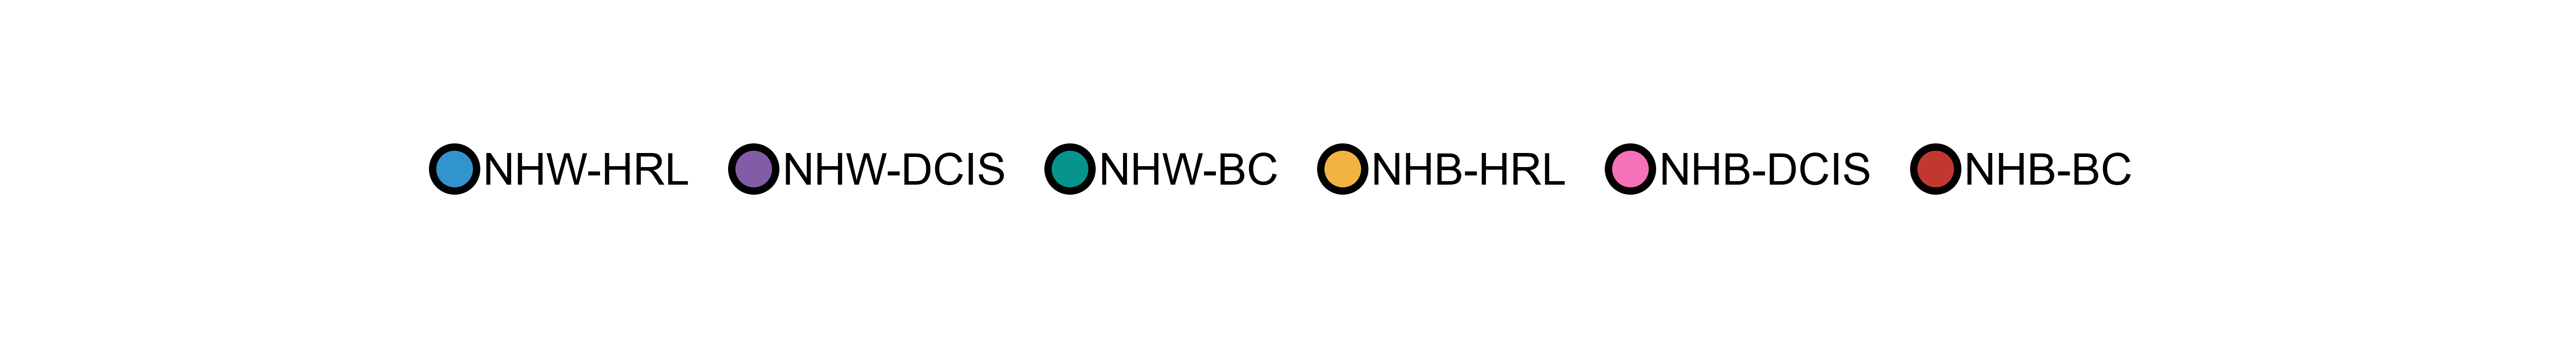

In [66]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Define color mapping
color_set = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830'
}

# Order of legend items
legend_labels = list(color_set.keys())
legend_colors = [color_set[label] for label in legend_labels]

# Create circular marker legend handles
handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=color, markersize=6, label=label)
    for label, color in zip(legend_labels, legend_colors)
]

# Plot
fig, ax = plt.subplots(figsize=(6, 0.6))  # Adjust width as needed
ax.axis('off')

# Add legend
ax.legend(
    handles=handles,
    loc='center',
    frameon=False,
    ncol=len(handles),
    handletextpad=0.4,
    columnspacing=1.2,
    fontsize=6,
    borderaxespad=0.0
)

# Save
plt.savefig("plots/Legends/colorlegend_stagerace.svg", bbox_inches='tight')
plt.show()

# By race

Pct by major cell type

## Calc ratio

Same as above

## Plot

In [95]:
dfp = pd.read_csv('data/Figure2/ratio_majorCellTypes.csv', index_col=0)
dfp

,dataset_name,Naive B,Mature B,Memory B,Plasmablast,Naive CD4T,Central Memory CD4T,Effector Memory CD4T,Cytotoxic CD4T,Treg,...,CD56-bright NK,Proliferating NK,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
0,Pool137_14,58.190045,30.950226,9.683258,1.176471,31.478294,36.163702,4.934022,0.382482,4.245554,...,7.512953,1.208981,1,91,HRL,NHW,42.5,N,Y,NHW-HRL
1,Pool138_15,18.892900,58.122744,21.780987,1.203369,31.011236,30.458081,4.909248,0.414866,2.886776,...,15.130435,1.391304,2,89,HRL,NHW,42.8,N,N,NHW-HRL
2,Pool138_14,60.820595,22.687047,12.791633,3.700724,35.240546,30.251435,4.850525,0.178183,2.712334,...,9.687034,2.384501,2,93,HRL,NHW,43.7,N,N,NHW-HRL
3,Pool137_26,35.575827,51.197263,12.314709,0.912201,31.237230,35.550511,6.106697,0.385925,2.542565,...,11.111111,0.750751,1,91,HRL,NHW,53.1,N,N,NHW-HRL
4,Pool138_9,50.688705,32.323232,16.528926,0.459137,19.293326,38.600673,7.501402,0.210320,2.706113,...,4.545455,1.704545,2,98,HRL,NHW,57.7,N,Y,NHW-HRL
5,Pool137_25,17.689906,65.972945,15.504683,0.832466,27.913496,43.932719,10.812976,0.841009,2.843412,...,14.356436,4.455446,1,90,HRL,NHW,59.6,N,N,NHW-HRL
6,Pool137_29,57.598039,26.593137,13.480392,2.328431,30.958502,34.300404,3.562248,1.615865,1.799486,...,7.022472,1.966292,1,90,HRL,NHW,59.6,N,N,NHW-HRL
7,Pool138_4,77.103867,11.144807,10.614102,1.137225,33.834004,40.693713,6.054506,0.340663,4.056984,...,10.821382,1.173403,2,94,HRL,NHW,60.5,N,Y,NHW-HRL
8,Pool137_10,59.555556,25.777778,12.000000,2.666667,33.627137,42.174145,4.326923,0.320513,2.297009,...,4.077670,2.135922,1,88,HRL,NHW,62.3,N,N,NHW-HRL
9,Pool137_6,36.349693,36.042945,26.533742,1.073620,19.508058,31.580435,4.778061,0.310998,2.685892,...,6.934307,2.189781,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [106]:
from statannotations.Annotator import Annotator
from scipy.stats import f_oneway

dfp['race-stage'] = pd.Categorical(
    dfp['race-stage'],
    categories=['NHW-HRL','NHB-HRL',  'NHW-DCIS','NHB-DCIS',  'NHW-BC','NHB-BC'],
    ordered=True
    )

color_set = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830'

# 'Diabetes':'#F472B6',
# 'Obesity':'#F59E42'

}

major_celltype_palette = {
    'B':    '#3072C4',   # strong blue
    'T':    '#EF763F',   # bold orange
    'DC':   '#35A293',   # teal
    'Mono': '#B3813E',   # rich brown/gold
    'NK':   '#7D4C99',   # deep purple
}

cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}



# Define the group for each pair (extract the trailing substring after '-' from NHW-HRL, etc.)
def get_group(pair):
    # E.g., ('NHW-HRL', 'NHB-HRL') -> 'HRL'
    return pair[0].split('-')[1]

def pval_to_star(p):
    # Customize as you wish (this is standard)
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

def get_group_from_celltype(celltype, cells_group):
    for group, members in cells_group.items():
        if celltype == members or celltype in members:
            return group
    return None



# --------- Settings ---------
ncol = 5
features =  cells_ordered  # the cell type names
nrow = int(np.ceil(len(features)/ncol))
figwidth = 7
figheight = nrow * 1.2      # or adjust as needed

fig, axs = plt.subplots(nrow, ncol, figsize=(figwidth, figheight), sharex=True)

axs = axs.flatten()

for i, yname in enumerate(features):
    ax = axs[i]
    sns.boxplot(
        data=dfp,
        x='race-stage',
        y=yname,
        hue='race-stage',
        palette=color_set,
        flierprops=dict(marker='o', markersize=2, alpha=0.7),
        ax=ax,
        showfliers=True
    )
    sns.stripplot(
        data=dfp, x='race-stage', y=yname, size=2, color='black', alpha=.3, ax=ax
    )


    n_cat = dfp['race-stage'].nunique()
    
    # boundaries for 2+2+2 split
    split_positions = [n_cat/3 - 0.5, 2*n_cat/3 - 0.5]  # 6 → [1.5, 3.5]
    
    for x in split_positions:
        ax.axvline(
            x=x,
            linestyle=':',
            color='gray',
            alpha=0.5,
            linewidth=1
        )
    
    pairs = [
        ('NHW-HRL', 'NHB-HRL'),
        ('NHW-DCIS', 'NHB-DCIS'),
        ('NHW-BC', 'NHB-BC')
    ]
    
    # --- Prepare custom pvalues (and stars) ---
    custom_annotations = []
    for pair in pairs:
        group = get_group(pair)
        # Get p-value from res for this celltype and group
        try:
            p = res.loc[yname].query("group == @group")['p_values'].iloc[0]
        except Exception:
            p = 1.0  # fallback if not found
        # Convert to star (or keep as e.g. f"p={p:.2g}")
        custom_annotations.append(p)

    annotator = Annotator(
        ax, pairs, data=dfp, x='race-stage', y=yname
    )
    

    annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', comparisons_correction=None, hide_non_significant=True)
    annotator.apply_and_annotate()

    groupname = get_group_from_celltype(yname, cells_group)
    groupname = f'{groupname} cells' if groupname!='Mono' else 'Monocytes'
    title_color = major_celltype_palette.get(groupname, 'black')


    ax.set_title(yname, fontsize=7, color='k', fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(f'Percentage of {groupname}')  # Hide to save space
    ax.tick_params(axis='x', labelsize=6, rotation=90)
    ax.tick_params(axis='y', labelsize=6)
    ax.legend([],[], frameon=False)  # Remove legend
    ax.set_xticklabels('')

    # for tick_label in ax.get_xticklabels():
    #     group = tick_label.get_text()
    #     if group in color_set:
    #         tick_label.set_color(color_set[group])

    

# Hide any unused subplots
for j in range(i+1, len(axs)):
    axs[j].set_visible(False)

group_palette = {
    'HRL': '#F5C16C',   # light gold
    'DCIS': '#EA7D30',  # orange
    'BC': '#7A491A',    # deep brown (darkest)
}

# Mapping from tick positions (0-based index) to group labels
tick_groups = {
    (0, 1): 'HRL',
    (2, 3): 'DCIS',
    (4, 5): 'BC'
}



# Shared axis label
fig.text(0.5, 0.04, '', ha='center', fontsize=7)
fig.text(0.03, 0.5, 'Cell Percentage', va='center', rotation='vertical', fontsize=7)

plt.tight_layout(rect=[0.04, 0.04, 1, 1])  # leave space for axis labels
plt.savefig('plots/F2/cellpctbox_byracegroup_withinMajorCelltype.svg', bbox_inches='tight', dpi=600)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcox

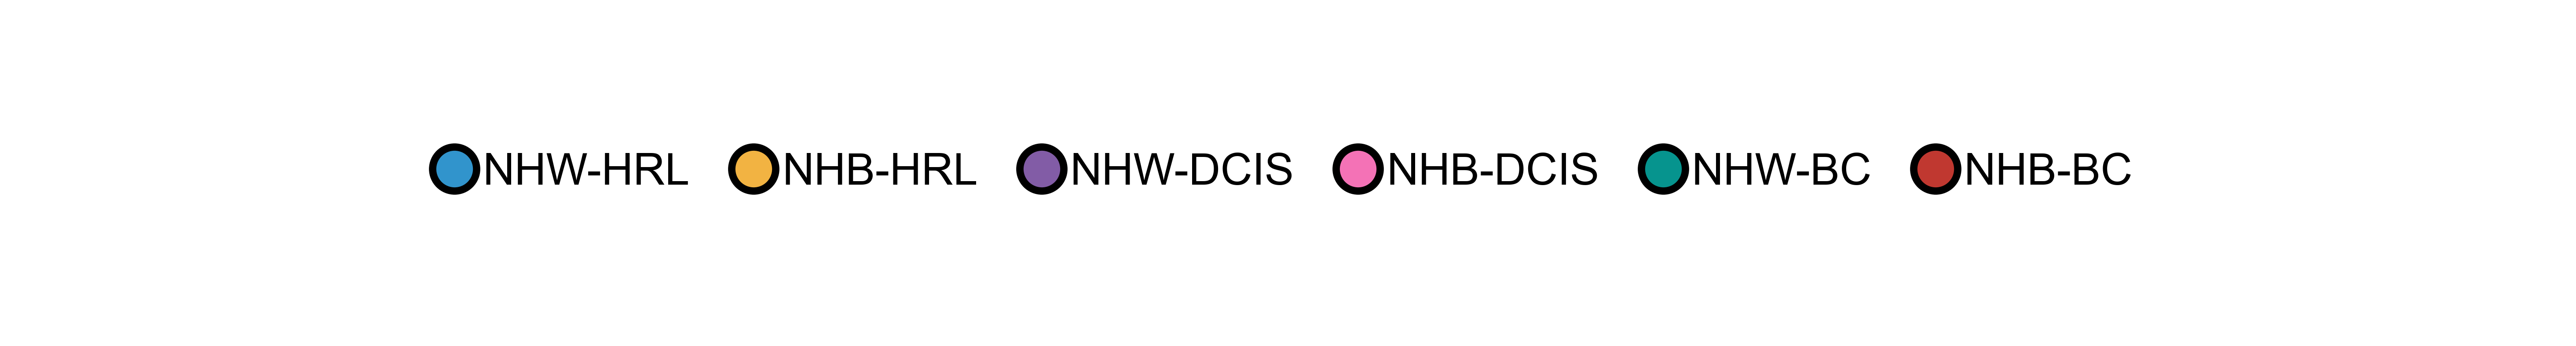

In [97]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Define color mapping
color_set = {
    'NHW-HRL':'#3194CC',
    'NHB-HRL':'#F2B342',
    
    'NHW-DCIS':'#825CA6',
    'NHB-DCIS':'#F472B6',
    
    'NHW-BC':'#06948E',
    'NHB-BC':'#C03830'
}

# Order of legend items
legend_labels = list(color_set.keys())
legend_colors = [color_set[label] for label in legend_labels]

# Create circular marker legend handles
handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=color, markersize=6, label=label)
    for label, color in zip(legend_labels, legend_colors)
]

# Plot
fig, ax = plt.subplots(figsize=(6, 0.6))  # Adjust width as needed
ax.axis('off')

# Add legend
ax.legend(
    handles=handles,
    loc='center',
    frameon=False,
    ncol=len(handles),
    handletextpad=0.4,
    columnspacing=1.2,
    fontsize=6,
    borderaxespad=0.0
)

# Save
plt.savefig("plots/Legends/colorlegend_racestage_figS2.svg", bbox_inches='tight')
plt.show()

# Save plot settings

In [27]:
plt_race_stage = {
    'NHW-HRL':'#DDF1F5',
    'NHW-DCIS':'#BAB4D8',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F4E6AA',
    'NHB-DCIS':'#A28070',
    'NHB-BC':'#C03830',
    
    'Diabetes':'#F472B6',
    'Obesity':'#F59E42'

}

plt_major_celltype = {
    'B':    '#3072C4',   # strong blue
    'T':    '#EF763F',   # bold orange
    'DC':   '#35A293',   # teal
    'Mono': '#B3813E',   # rich brown/gold
    'NK':   '#7D4C99'   # deep purple
}

cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}

import seaborn as sns
import random

n = 25
colors = sns.color_palette('tab20', 20) + sns.color_palette('Set3', 5)

random.seed(1024)
random.shuffle(colors)  # simple option, or design a custom reordering

plt_celltype = dict(zip(cells_ordered, colors))

In [28]:
plt_data = {
    'plt_race_stage':plt_race_stage,
    'plt_major_celltype':plt_major_celltype,
    'cells_group':cells_group,
    'plt_celltype':plt_celltype
}

with open('data/Legends/palette.pkl','wb') as f:
    pkl.dump(plt_data,f)
